In [691]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import datasets
from torchvision.transforms import ToTensor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import csv
from pathlib import Path

import math

In [692]:
results_file = Path("max_norm_results.csv")

if not results_file.exists():
    with open(results_file, "w", newline="") as file:
        writer = csv.writer(file)
        writer.writerow([
            "max_norm",
            "rounds",
            "seed",
            "client1_accuracy",
            "client2_accuracy",
            "client3_accuracy",
            "client1_loss",
            "client2_loss",
            "client3_loss",
        ])

print(f"Results will be saved to: {results_file.resolve()}")

Results will be saved to: /Users/rajveerpatter/Documents/GitHub/federated_learning_playground/02_federated_learning/max_norm_results.csv


## Handling the dataset

In [693]:
# import datasets
training_data = datasets.MNIST(
    root="../data",
    train=True,
    download=False,
    transform=ToTensor() # scaling the pixel values from 0 -> 255 to 0 -> 1
)

print(len(training_data))

test_data = datasets.MNIST(
    root="../data",
    train=False,
    download=False,
    transform=ToTensor()
)

print(len(test_data))

60000
10000


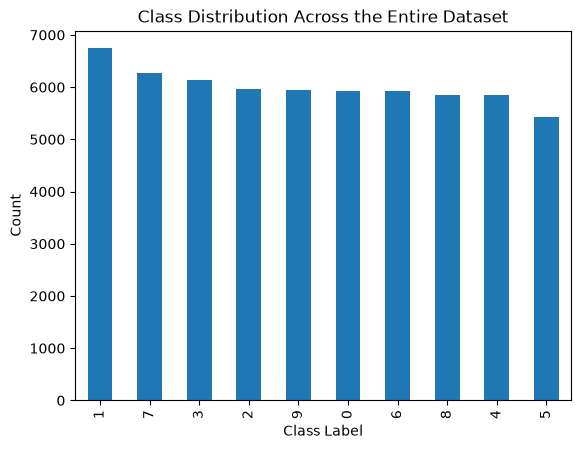

In [694]:
all_labels = []

for _, labels in training_data:
    all_labels.append(labels)

pd.Series(all_labels).value_counts().plot(kind="bar")
plt.title("Class Distribution Across the Entire Dataset")
plt.xlabel("Class Label")
plt.ylabel("Count")
plt.show()

In [695]:
# This prints each digit and its exact count
counts = pd.Series(all_labels).value_counts()
print(counts)

1    6742
7    6265
3    6131
2    5958
9    5949
0    5923
6    5918
8    5851
4    5842
5    5421
Name: count, dtype: int64


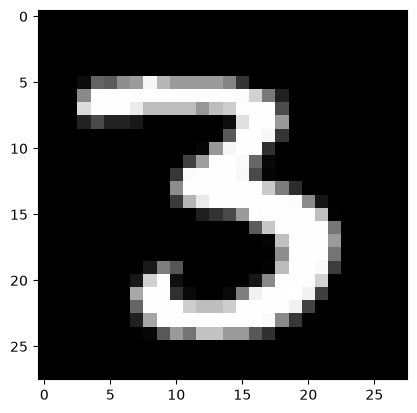

In [696]:
image_three, label_three = training_data[12]
image = image_three.unsqueeze(0)

plt.imshow(image.squeeze(), cmap="gray")
plt.show()

### Make the data for each client non-IID
- client1 - more data consisting of 0,1,2,3
- client2 - more data consisting of 4,5,6
- client3 - more data consisting of 7,8,9

Using **Dirichlet distribution**:
Dirichlet distribution is a standard method in machine learning, especially in Federated Learning (FL), to partition a centralized dataset into non-IID (non-independent and identically distributed) client splits

In [697]:
client1_train_data, client2_train_data, client3_train_data = random_split(
    training_data,
    [20000,20000,20000]
)

print(len(client1_train_data))
print(len(client2_train_data))
print(len(client3_train_data))

20000
20000
20000


In [698]:
client1_test_data, client2_test_data, client3_test_data = random_split(
    test_data,
    [3333,3333,3334]
)

print(len(client1_test_data))
print(len(client2_test_data))
print(len(client3_test_data))

3333
3333
3334


In [699]:
# dataloader
def create_dataloaders(train_data, test_data):
    train_data_loader = DataLoader(
        train_data,
        batch_size=64,
        shuffle=True
    )

    test_data_loader = DataLoader(
        test_data,
        batch_size=64,
        shuffle=True
    )

    return train_data_loader, test_data_loader

In [700]:
client1_train_loader, client1_test_loader = create_dataloaders (
    client1_train_data,
    client1_test_data
)

client2_train_loader, client2_test_loader = create_dataloaders (
    client2_train_data,
    client2_test_data
)

client3_train_loader, client3_test_loader = create_dataloaders (
    client3_train_data,
    client3_test_data
)

In [701]:
images, labels = next(iter(client1_train_loader))

print(images.shape)
print(labels.shape)

torch.Size([64, 1, 28, 28])
torch.Size([64])


In [702]:
class MLP(nn.Module):
    def __init__(self):
        super().__init__()
        
        # flatten layer
        # self.flatten = nn.flatten() # input [1,28,28] flattened input 1x28x28 = 784
        
        # define linear layers
        self.fcl1 = nn.Linear(784,128)
        self.fcl2 = nn.Linear(128,64)
        self.fcl3 = nn.Linear(64, 10)

    def forward(self,x):
        x = torch.flatten(x,1)
        x = F.relu(self.fcl1(x))
        x = F.relu(self.fcl2(x))
        x = self.fcl3(x)
        return x

### Minimal Federated learning model
without using flower 

Training each client, with a leanrning rate of 0.005 and Adam optimiser:
| Client   | Accuracy | Precison | Recall   | F1-score  | Loss      |
| -------- | -------- | -------- | -------- |  -------- |  -------- |
| Client 1 | 95.65%   |          |          |           |   0.16    |
| Client 2 | 95.34%   |          |          |           |   0.15    |
| Client 3 | 95.80%   |          |          |           |   0.14    | 


In [703]:
global_model = MLP()

client1_model = MLP()
client2_model = MLP()
client3_model = MLP()

In [704]:
loss_function = nn.CrossEntropyLoss() 

# define each models own optimiser 
client1_optimiser = optim.Adam(
    client1_model.parameters(), 
    lr=0.005
)

client2_optimiser = optim.Adam(
    client2_model.parameters(), 
    lr=0.005
)

client3_optimiser = optim.Adam(
    client3_model.parameters(), 
    lr=0.005
)

In [705]:
def train_client(epochs, client, loader, loss_function, optimiser, model):
    for epoch in range(epochs):
        print(f"{client}: Starting training for epoch {epoch} ...")
    
        running_loss = 0.0
    
        for index, data in enumerate(loader):
            inputs, label = data
    
            optimiser.zero_grad()
            
            outputs = model(inputs)
    
            loss = loss_function(outputs, label)
            loss.backward()
            optimiser.step()
    
            running_loss += loss.item()
    
        print(f'{client}:Loss: {running_loss / len(loader):.4f}')
    return model
        
    #torch.save(model.state_dict(), f'trained_{client}_mlp.pth')

In [706]:
def test_client(client, model, loader):
    
    model.eval()

    # test the model
    correct = 0
    running_loss = 0
    total = 0

    all_labels, all_predicted = [], []
    
    with torch.no_grad():
        for index, data in enumerate(loader):
            inputs, label = data
    
            outputs = model(inputs)
    
            _, predicted = torch.max(outputs, 1)
            total += label.size(0)

            loss = loss_function(outputs, label)
            running_loss += loss.item() * label.size(0)
            
            correct += (predicted == label).sum().item()

            all_predicted.extend(predicted)
            all_labels.extend(label)
            
    
    accuracy = 100* correct / total
    average_loss = running_loss / total
    
    print(f'{client} test accuracy: {accuracy}%')
    print(f'{client} test average loss: {average_loss}')
    return accuracy, average_loss, all_labels, all_predicted

In [707]:
def evaluate_client(client, y_true, y_pred):
    cr = classification_report(y_true, y_pred)
    print(f"{client} classification report")
    print("\n",cr)

    cm = confusion_matrix(y_true, y_pred)
    display_cm = ConfusionMatrixDisplay(confusion_matrix=cm)
    display_cm.plot()

    plt.show()
    
    

### Client 1

### Client 2

### Client 3

## FedAvg

https://medium.com/@joemuthui18/day-2-understanding-and-implementing-federated-averaging-fedavg-e8d1d523b155

In [708]:
def server_fedAvg(global_weights, client_sizes, client_weights):
    total_size = sum(client_sizes)

    aggregated_weights = {
        key: torch.zeros_like(client_weights[0][key])
        for key in client_weights[0]
    }


    for client, size in zip(client_weights, client_sizes):
        weight = size / total_size
        
        for key in aggregated_weights:
            aggregated_weights[key] += client[key] * weight
            
    new_global_weights = {
        key: global_weights[key] + aggregated_weights[key]
        for key in global_weights
    }
    return new_global_weights
    

## Differential privacy

In [709]:
def clip_client_updates(
    global_weights,
    local_weights,
    max_norm
):

    # Clipping updates 
    
    # calculate the updates
    updates = {
        key: local_weights[key] - global_weights[key]
        for key in global_weights
    }
    # combined L2 of each update norm of the entire client update
    total_norm = torch.sqrt(
        sum(torch.sum(update ** 2) for update in updates.values())
    )

    # clipping factor 
    # 1e-12 prevent dividing by 0
    clipping_factor = min(1.0, max_norm / (total_norm.item() + 1e-12))
    
    # clip the client updates
    clipped_updates = {
        key: update * clipping_factor
        for key, update in updates.items()
    }


    clipped_norm = torch.sqrt(
        sum(
            torch.sum(update ** 2)
            for update in clipped_updates.values()
        )
    )

    print("Original L2 norm:", total_norm.item())
    print("Clipped L2 norm:", clipped_norm.item())
    print("Maximum allowed norm:", max_norm)
    print("Clipping worked:", clipped_norm.item() <= max_norm + 1e-6)

    return clipped_updates

In [710]:
def aggregate_client_updates(global_weights, clipped_updates_list, client_sizes):
    total_size = sum(client_sizes)

    # each client would have the same key for example [layer1.weight], we aggregate all the weights and biases updates given by each client
    aggregated_updates = {
        key: torch.zeros_like(clipped_updates_list[0][key])
        for key in clipped_updates_list[0]
    }

    for client_update, client_size in zip(
        clipped_updates_list, client_sizes
    ):
        # calculate the client weight 
        weight = client_size / total_size

        for key in aggregated_updates:
            aggregated_updates[key] += weight * client_update[key]

    clipped_weights = {
        key: global_weights[key] + aggregated_updates[key]
        for key in global_weights
    }

    return clipped_weights
        

### adding gaussian noise

tried using noise_std, will replace this and use noise multiplier instead

In [711]:
def add_noise(global_weights, clipped_client_update, sensitivity):
    # Differential privacy

    # define delta and epsilon
    # delta = 0.00001 # 10^-5
    # epsilon = 5.0 # we can test different epsilon has to be <=1

    
    # noise_std = (sensitivity * math.sqrt(2 * math.log(1.25 / delta)) / epsilon)

    noise_multiplier = 0.03 # experiment with different values 
    noise_std = noise_multiplier * sensitivity
    
    noisy_update = {}

    # Generate gaussian noise
    # generating random values with the shape as each clipped_update
    
    for key, update in clipped_client_update.items():
        noise = torch.randn_like(update) * noise_std
        noisy_update[key] = update + noise
        

    # Pass back the new weights (clipped & noise added) for the client 
    # private_weights = {
    #     key: global_weights[key] + nosied_update[key]
    #     for key in global_weights
    # }

    print("Sensitivity:", sensitivity)
    print("Noise std:", noise_std)
    
    for key, update in clipped_client_update.items():
        actual_noise = noisy_update[key] - update
        
        print(
            key,
            "update RMS:", update.pow(2).mean().sqrt().item(),
            "noise RMS:", actual_noise.pow(2).mean().sqrt().item()
        )

    return noisy_update

## Federated learning rounds

In [712]:
def federated_round(round_number, max_norm, seed):
    print(f"\n--- Federated Round {round_number} ---")

    # Create fresh optimizers
    client1_optimiser = torch.optim.Adam(
        client1_model.parameters(), lr=0.001
    )
    client2_optimiser = torch.optim.Adam(
        client2_model.parameters(), lr=0.001
    )
    client3_optimiser = torch.optim.Adam(
        client3_model.parameters(), lr=0.001
    )

    # Send the current global weights to every client
    client1_model.load_state_dict(global_model.state_dict())
    client2_model.load_state_dict(global_model.state_dict())
    client3_model.load_state_dict(global_model.state_dict())

    # global weights
    global_weights = {
        key: value.detach().clone()
        for key, value in global_model.state_dict().items()
    }

    # Train each client locally
    print(f"\n--- Training Client 1 ---")
    train_client(3, "Client 1", client1_train_loader,
                 loss_function, client1_optimiser, client1_model)

    print(f"\n--- Training Client 2 ---")
    train_client(3, "Client 2", client2_train_loader,
                 loss_function, client2_optimiser, client2_model)

    print(f"\n--- Training Client 2 ---")
    train_client(3, "Client 3", client3_train_loader,
                 loss_function, client3_optimiser, client3_model)

    # Collect updated client weights
    client_weights = [
        client1_model.state_dict(),
        client2_model.state_dict(),
        client3_model.state_dict()
    ]

    client_sizes = [
        len(client1_train_loader.dataset),
        len(client2_train_loader.dataset),
        len(client3_train_loader.dataset)
    ]

    total_size = sum(client_sizes)

    client_size_weights = {
        size / total_size
        for size in client_sizes
    }

    max_client_weight = max(client_size_weights)
    
    clipped_client_weights = [
        clip_client_updates(global_weights, local_weights, max_norm)
        for local_weights in client_weights
    ]

    # aggregate the client updates
    # aggregated_clipped_client_updates = aggregate_client_updates(global_weights, clipped_client_weights, client_sizes)

    # Add gaussian noise to the aggregated client updates
    sensitivity = 2 * max_client_weight * max_norm
    
    noisy_client_updates = [
        add_noise(global_weights, clipped_update, sensitivity)
        for clipped_update in clipped_client_weights
    ]

    # Aggregate the client weights
    aggregated_weights = server_fedAvg(global_weights, client_sizes, noisy_client_updates) # get the new global model weights

    # Update the global model
    global_model.load_state_dict(aggregated_weights)

    # Evaluate the global model on each client's local test data
    print(f"\n--- Evaluating Client 1 ---")
    acc1, loss1, all_labels1, all_pred1 = test_client("Client 1", global_model, client1_test_loader)
 
    print(f"\n--- Evaluating Client 2 ---")
    acc2, loss2, all_labels2, all_pred2 = test_client("Client 2", global_model, client2_test_loader)
    
    print(f"\n--- Evaluating Client 3 ---")
    acc3, loss3, all_labels3, all_pred3 = test_client("Client 3", global_model, client3_test_loader)

    # with open(results_file, "a", newline="") as file:
    #     writer = csv.writer(file)
    #     writer.writerow([
    #         max_norm,
    #         round_number,
    #         seed,
    #         acc1, acc2, acc3,
    #         loss1, loss2, loss3,
    #     ])

    # print(f"Results saved for max_norm={max_norm}, round={round_number}")

In [713]:
def reset_experiment(seed):
    global global_model, client1_model, client2_model, client3_model


    # Reset random initialisation
    torch.manual_seed(seed)

    # Create fresh models
    global_model = MLP()

    client1_model = MLP()
    client2_model = MLP()
    client3_model = MLP()


    print("Experiment reset.")


In [714]:
# for seed in range(5):
#     for max_norm in [float("inf"), 1.0, 10.0, 15.0, 20.0, 30.0, 35.0, 40.0]:
#         reset_experiment(seed)
#         for r in range(1, 7):
#             federated_round(r, max_norm, seed)

reset_experiment(42)
for r in range(1, 7):
    federated_round(r, max_norm=5.0, seed=42)

Experiment reset.

--- Federated Round 1 ---

--- Training Client 1 ---
Client 1: Starting training for epoch 0 ...
Client 1:Loss: 0.5616
Client 1: Starting training for epoch 1 ...
Client 1:Loss: 0.2471
Client 1: Starting training for epoch 2 ...
Client 1:Loss: 0.1834

--- Training Client 2 ---
Client 2: Starting training for epoch 0 ...
Client 2:Loss: 0.5622
Client 2: Starting training for epoch 1 ...
Client 2:Loss: 0.2490
Client 2: Starting training for epoch 2 ...
Client 2:Loss: 0.1868

--- Training Client 2 ---
Client 3: Starting training for epoch 0 ...
Client 3:Loss: 0.5567
Client 3: Starting training for epoch 1 ...
Client 3:Loss: 0.2423
Client 3: Starting training for epoch 2 ...
Client 3:Loss: 0.1819
Original L2 norm: 15.986272811889648
Clipped L2 norm: 5.0
Maximum allowed norm: 5.0
Clipping worked: True
Original L2 norm: 16.006885528564453
Clipped L2 norm: 4.999999523162842
Maximum allowed norm: 5.0
Clipping worked: True
Original L2 norm: 15.94440746307373
Clipped L2 norm: 5

Predicted: 0
Actual: 0


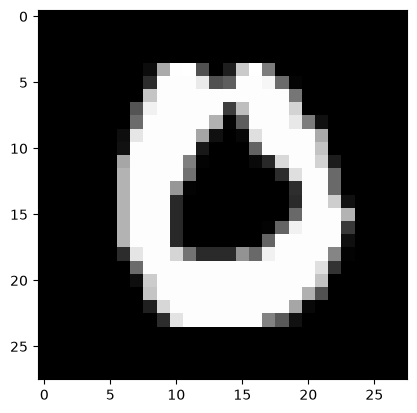

Predicted: 1
Actual: 1


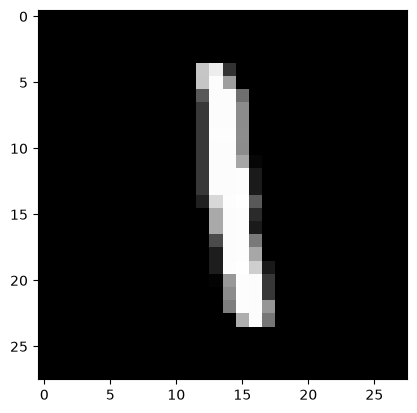

Predicted: 7
Actual: 7


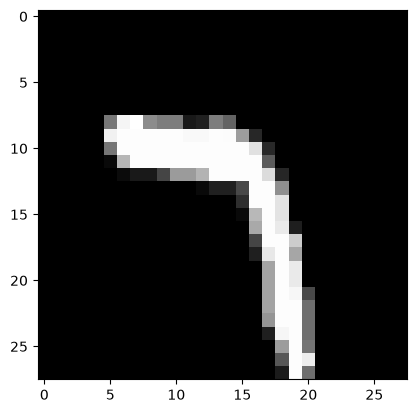

Predicted: 0
Actual: 0


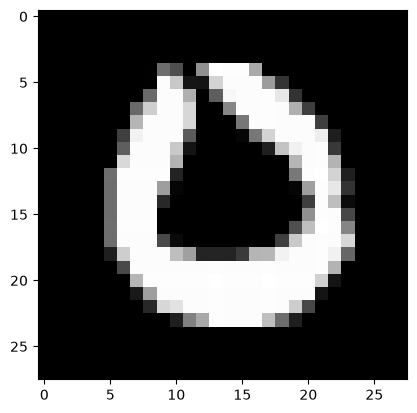

Predicted: 6
Actual: 6


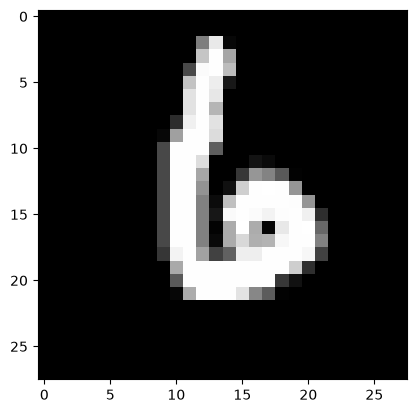

Predicted: 9
Actual: 8


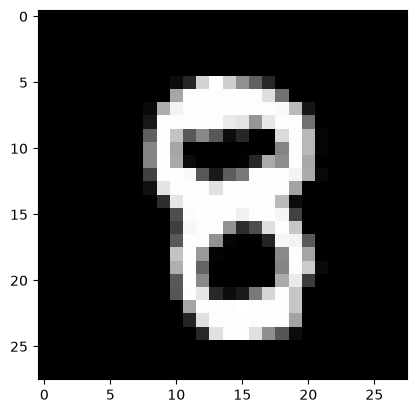

Predicted: 9
Actual: 9


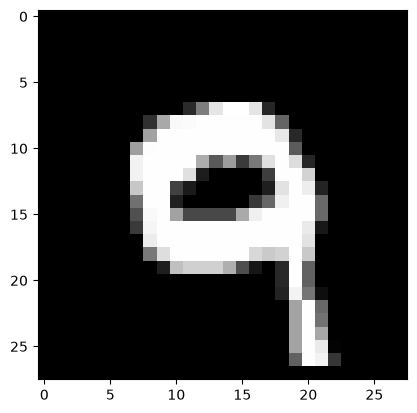

Predicted: 9
Actual: 5


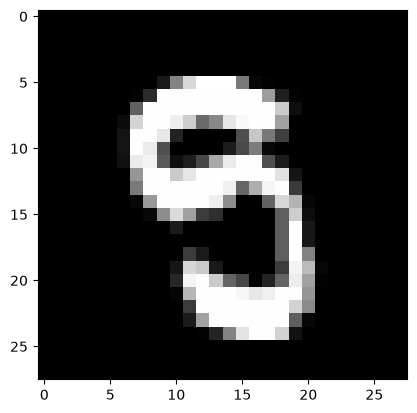

Predicted: 1
Actual: 1


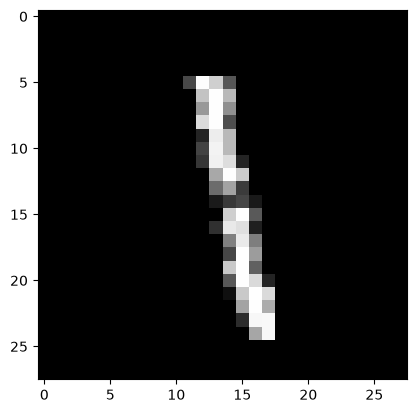

Predicted: 7
Actual: 7


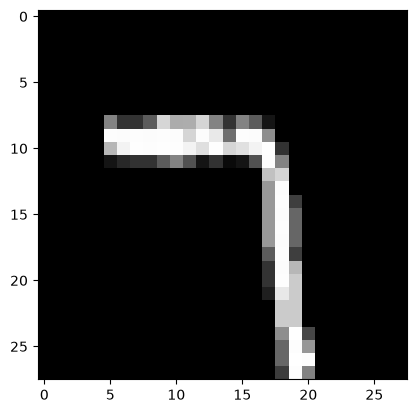

In [715]:
global_model.eval()

for i in range(5990,6000):
    image, label = test_data[i]
    with torch.no_grad():
        output = global_model(image.unsqueeze(0))
        _,predicted = torch.max(output,1)
    
    print("Predicted:", predicted.item())
    print("Actual:", label)
    
    plt.imshow(image.squeeze(), cmap="gray")
    plt.show()